# Tugas Besar 2 IF3170 Inteligensi Artifisial

Prediksi pembatalan pemesanan penginapan.

## Group 31 - Kelompok Dadakan

- Farrel Limjaya (13524046)
- Raymond Jonathan Dwi Putra Julianto (13524059)
- Reynard Anderson Wijaya (13524111)
- Fauzan Mohamad Abdul Ghani (13524113)
- Hasna Nurul Alimah (11424061)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

Pemesanan yang dibatalkan dapat menyisakan kamar kosong. Prediksi sebelum kedatangan membantu penginapan merencanakan pengingat dan kebijakan pemesanan.

## Overview

Setiap baris mewakili satu pemesanan. Fitur mencakup jumlah tamu, lama menginap, pilihan kamar dan makanan, harga, serta riwayat pemesanan tamu.

## Aim

Menyiapkan data untuk memprediksi `is_canceled`: 1 berarti dibatalkan, 0 berarti tidak dibatalkan. Tahap berikutnya membandingkan lima model from scratch dengan scikit-learn.

## Metric

Kompetisi menggunakan Macro F1, yaitu rata-rata F1 untuk kelas tidak dibatalkan dan dibatalkan.

## Dataset

`train.csv` memiliki label `is_canceled`. `test.csv` tidak memiliki label dan digunakan untuk submission. `sample_submission.csv` menunjukkan kolom hasil yang diminta: `id` dan `is_canceled`.

| Kolom | Arti |
|---|---|
| `id` | Identitas unik pemesanan; disimpan sebagai teks. |
| `num_adults`, `num_children` | Jumlah tamu dewasa dan anak. |
| `weekend_nights`, `weekday_nights` | Jumlah malam akhir pekan dan hari kerja. |
| `meal_package` | Paket makanan. |
| `needs_parking` | Kebutuhan parkir: 0 atau 1. |
| `room_category` | Jenis kamar; huruf A?G tidak menunjukkan urutan kualitas. |
| `days_before_arrival` | Jarak hari dari pemesanan ke kedatangan. |
| `arrival_year`, `arrival_month`, `arrival_day` | Tanggal kedatangan. |
| `booking_channel` | Saluran pemesanan. |
| `is_returning_guest` | Pernah menginap sebelumnya: 0 atau 1. |
| `prior_cancellations`, `prior_completed_bookings` | Jumlah pemesanan sebelumnya yang dibatalkan dan tidak dibatalkan. |
| `nightly_rate_idr` | Harga rata-rata per kamar per malam; nol biasanya berarti gratis. |
| `special_requests` | Jumlah permintaan khusus. |
| `is_canceled` | Target pembatalan: 0 atau 1. |

## Approach

Periksa kualitas data, pisahkan training dan validasi, lalu isi nilai kosong dan ubah fitur menjadi angka. Median, modus, kategori encoding, dan parameter standardisasi hanya dipelajari dari bagian training. Model belum dilatih pada notebook ini.

---

# Initialization <a name="2"></a>

---

Lingkungan yang dibutuhkan: Python, NumPy, pandas, scikit-learn, dan Matplotlib.

## Environment Setup

Jalankan baris instalasi hanya jika pustakanya belum tersedia.

In [1]:
# %pip install numpy pandas "scikit-learn>=1.2" matplotlib

## Import Libraries

In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

## Settings

Path dicari dari lokasi notebook atau folder proyek. Kode preprocessing diimpor dari `src/code/preprocessing/preprocessing.py`.

In [3]:
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "train.csv").exists() and (p / "src").exists()
)
DATA_DIR = root / "data"
SEED = 42
sys.path.insert(0, str(root / "src" / "code"))

from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from preprocessing.preprocessing import create_preprocessor
from preprocessing.preprocessing import impute, encode, scale
from analysis.exploration import overview, plot_distributions, check_data, heatmap, missing_values, duplicates, outliers, validate_values
from models.decision_tree import DecisionTreeID3
from models.svm_working_set import WorkingSetSVM
from preprocessing.svm_safe_preprocessing import SafeSVMPreprocessor
from workflows.workflow import train_model, evaluate_model, compare_models, save_model, load_model, submit_model
from workflows.dtl_workflow import compare_pruning, train_final_dtl
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from models.naive_bayes import NaiveBayes
from preprocessing.nb_preprocessing import NaiveBayesPreprocessor

## Seed Everything

Seed yang sama digunakan pada pembagian data agar hasilnya dapat diulang.

In [4]:
np.random.seed(SEED)

## Load Dataset

CSV asli hanya dibaca. `id` tetap berupa teks dan tidak digunakan sebagai fitur.

In [5]:
train_df = pd.read_csv(DATA_DIR / "train.csv", dtype={"id": str})
test_df = pd.read_csv(DATA_DIR / "test.csv", dtype={"id": str})
submission_example = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"id": str})

assert "is_canceled" in train_df and "is_canceled" not in test_df
assert train_df.drop(columns="is_canceled").columns.equals(test_df.columns)
assert submission_example["id"].equals(test_df["id"])
print(f"Train: {train_df.shape} | Test: {test_df.shape}")
display(train_df.head())

Train: (27373, 19) | Test: (6844, 18)


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


---

# Data Understanding (Optional) <a name="3"></a>

---

Pemeriksaan awal mencatat bentuk data dan kondisi kolom. Statistik untuk mengisi nilai kosong dan standardisasi dihitung setelah pembagian training dan validasi.

## Describe Data

Kolom hitungan dapat terbaca sebagai float karena memuat nilai kosong. Itu tidak otomatis berarti nilainya salah.

In [6]:
display(overview(train_df))
display(train_df.describe().round(2))

,tipe,nilai_unik,kosong_train,persen_kosong_train
id,object,27373,0,0.00
num_adults,float64,5,809,2.96
num_children,float64,6,3035,11.09
weekend_nights,int64,8,0,0.00
weekday_nights,int64,18,0,0.00
meal_package,object,4,1760,6.43
needs_parking,float64,2,1082,3.95
room_category,object,7,1002,3.66
days_before_arrival,float64,407,1123,4.10
arrival_year,int64,2,0,0.00


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.00,24338.00,27373.00,27373.00,26291.00,26250.00,27373.00,27373.00,27373.00,27373.00,27373.00,27373.00,25335.00,24873.00,27373.00
mean,1.85,0.12,0.81,2.21,0.03,85.38,2023.82,7.40,15.54,0.03,0.02,0.14,1716979.55,0.67,0.33
std,0.52,0.43,0.88,1.42,0.17,85.97,0.38,3.07,8.77,0.16,0.36,1.69,587936.77,0.80,0.47
min,0.00,0.00,0.00,0.00,0.00,0.00,2023.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,0.00,0.00,1.00,0.00,17.00,2024.00,5.00,8.00,0.00,0.00,0.00,1338000.00,0.00,0.00
50%,2.00,0.00,1.00,2.00,0.00,58.00,2024.00,8.00,16.00,0.00,0.00,0.00,1644000.00,0.00,0.00
75%,2.00,0.00,2.00,3.00,0.00,126.00,2024.00,10.00,23.00,0.00,0.00,0.00,2019000.00,1.00,1.00
max,4.00,10.00,7.00,17.00,1.00,448.00,2024.00,12.00,31.00,1.00,13.00,58.00,9165000.00,5.00,1.00


## Explore Data

Distribusi kelas menunjukkan komposisi target. Histogram harga dan jarak pemesanan membantu mengenali rentang data; nilai besar belum tentu salah.

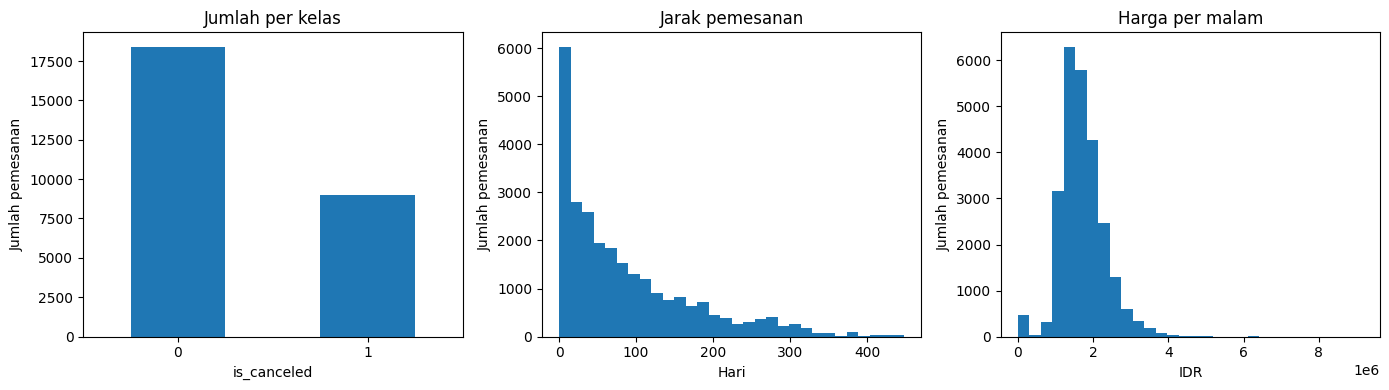

,jumlah
meal_package,
Breakfast,19654
Room Only,3713
Half Board,2242
NaN,1760
Full Board,4


,jumlah
room_category,
Type B,20447
Type G,4396
NaN,1002
Type A,699
Type D,514
Type C,189
Type F,119
Type E,7


,jumlah
booking_channel,
Online Travel Agent,17511
Offline Agent,7960
Corporate,1513
Complimentary,301
Airline,88


In [7]:
plot_distributions(train_df)
for kolom in ["meal_package", "room_category", "booking_channel"]:
    display(train_df[kolom].value_counts(dropna=False).rename("jumlah").to_frame())

## Verify Data Quality

Periksa identitas, label, duplikat, serta nilai kosong. Kesamaan seluruh fitur dengan `id` berbeda belum membuktikan pemesanan yang sama.

In [8]:
display(check_data(train_df, test_df))

,baris,baris_dengan_nilai_kosong,duplikat_seluruh_kolom,fitur_sama_id_berbeda
data,,,,
train,27373,10737,0,66
test,6844,2669,0,3


---

# Training and Validation Split <a name="4"></a>

---

Sebanyak 80% `train.csv` digunakan untuk training dan 20% untuk validasi. Stratifikasi menjaga proporsi label pada kedua bagian. `test.csv` tetap terpisah dan tidak digunakan untuk memilih parameter.

In [9]:
train_set, val_set = train_test_split(
    train_df, test_size=0.2, random_state=SEED, stratify=train_df["is_canceled"]
)
assert set(train_set["id"]).isdisjoint(val_set["id"])
assert len(train_set) + len(val_set) == len(train_df)
print("Training:", len(train_set), "| Validasi:", len(val_set))

Training: 21898 | Validasi: 5475


## Heatmap Korelasi (Tambahan)

Heatmap menampilkan korelasi Pearson antarfitur numerik dan target pada data training. Korelasi menunjukkan hubungan linear, bukan sebab akibat.

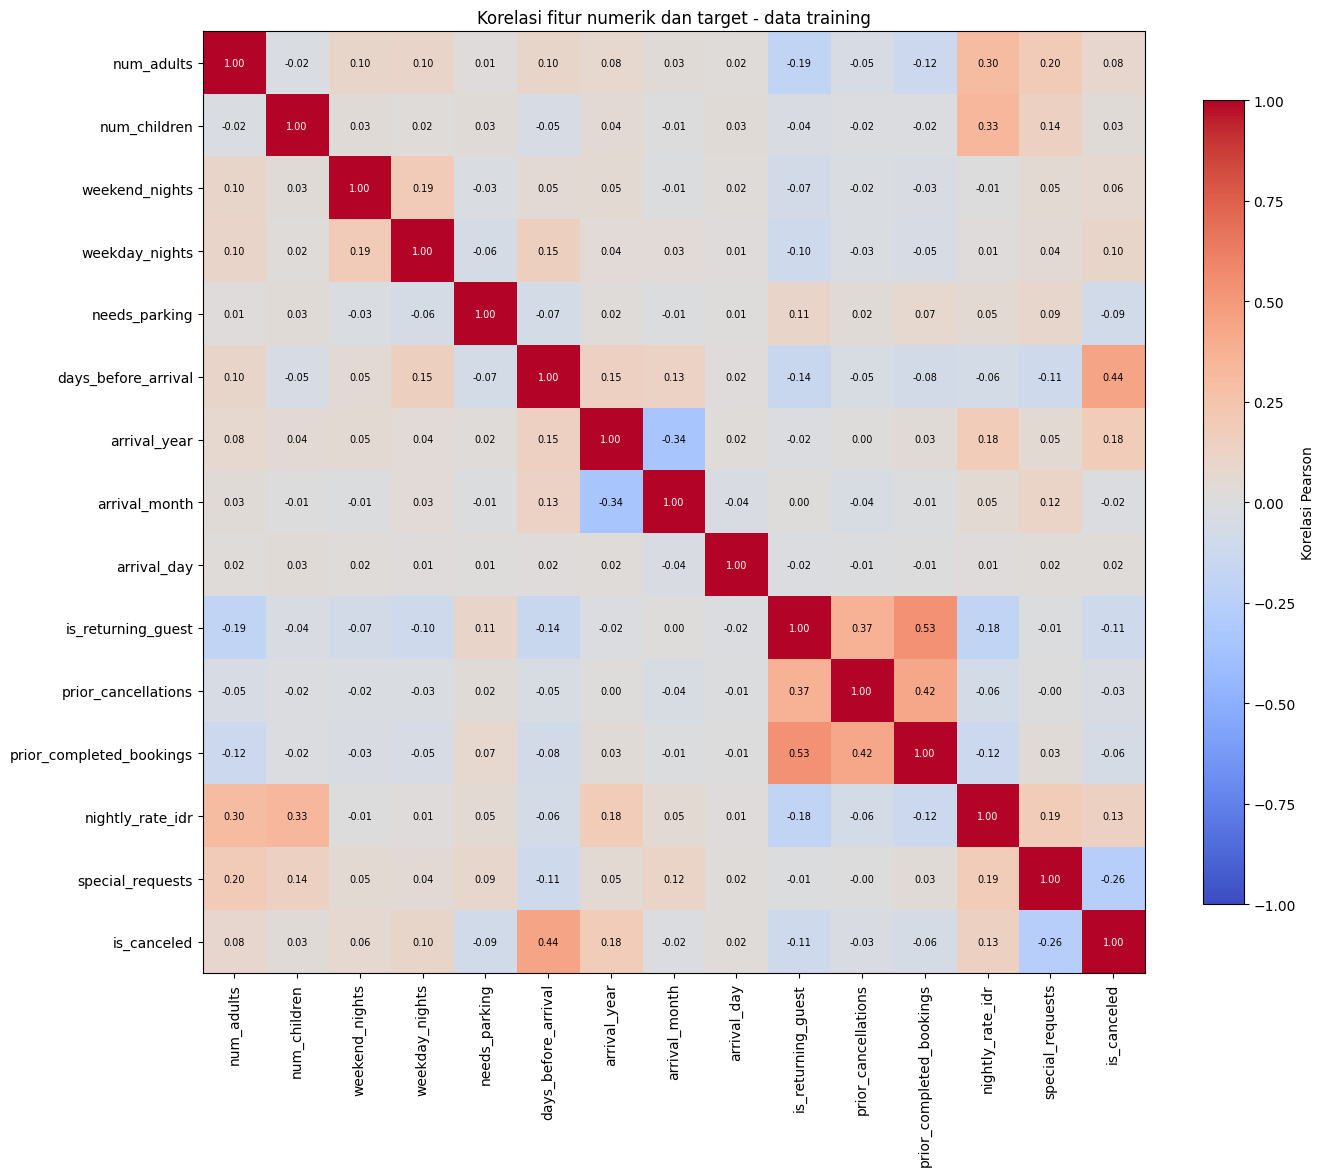

In [10]:
heatmap(train_set)

---

# Data Preparation <a name="5"></a>

---

Bagian berikut menyiapkan fitur. Nilai pengisi, parameter scaling, dan kategori dipelajari dari data training.

Preprocessing memakai scikit-learn melalui modul Python yang sudah dibuat. Larangan menggunakan model siap pakai tetap berlaku untuk implementasi model from scratch pada bagian selanjutnya.

## Select Data

Gunakan seluruh 17 fitur selain `id` dan target. Belum ada fitur yang dibuang berdasarkan korelasi atau skor model.

In [11]:
X_train = train_set.drop(columns=["id", "is_canceled"])
y_train = train_set["is_canceled"].copy()
X_valid = val_set.drop(columns=["id", "is_canceled"])
y_valid = val_set["is_canceled"].copy()
X_test = test_df.drop(columns="id")
id_test = test_df["id"].copy()

kolom_numerik = X_train.select_dtypes(include="number").columns.tolist()
kolom_kategori = X_train.select_dtypes(exclude="number").columns.tolist()
assert X_train.columns.equals(X_valid.columns) and X_train.columns.equals(X_test.columns)
print("Numerik:", kolom_numerik)
print("Kategori:", kolom_kategori)

Numerik: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Kategori: ['meal_package', 'room_category', 'booking_channel']


## Clean Data

Nilai kosong akan diisi tanpa menghapus baris. Data dengan nilai tidak valid diperiksa terlebih dahulu; nilai nol yang sah dipertahankan.

### Missing Values

Gunakan median untuk kolom numerik dan modus untuk kategori sebagai baseline. Nilai pengisi pada tabel berikut berasal dari training saja. Pada data ini, median kolom biner tetap 0 atau 1. Nilai kosong tidak dianggap sama dengan nol.

In [12]:
display(missing_values(X_train, X_valid, X_test))
X_train_clean, X_valid_clean, X_test_clean, imputers = impute(X_train, X_valid, X_test)

,kosong_training,kosong_validasi,kosong_test,nilai_pengisi_training
num_adults,636,173,180,2.0
num_children,2426,609,747,0.0
weekend_nights,0,0,0,1.0
weekday_nights,0,0,0,2.0
meal_package,1403,357,442,Breakfast
needs_parking,885,197,247,0.0
room_category,810,192,242,Type B
days_before_arrival,877,246,290,57.0
arrival_year,0,0,0,2024.0
arrival_month,0,0,0,8.0


### Duplicates

Tidak ditemukan ID atau baris lengkap yang duplikat. Beberapa pemesanan memiliki fitur sama dengan ID berbeda; baris tersebut dipertahankan karena belum terbukti sebagai kesalahan pencatatan. Kemiripan ini juga perlu diperhatikan saat menilai hasil validasi.

In [13]:
display(duplicates(train_set, val_set, X_train, X_valid))

Duplikat lengkap training: 0
Duplikat lengkap validasi: 0
Fitur sama dalam training: 41
Fitur sama dalam validasi: 4


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
3315,3d8aaa46,2.0,0.0,2,0,Half Board,0.0,Type B,388.0,2024,10,22,Offline Agent,0,0,0,NaN,1.0,1
4140,a7e0ef46,1.0,0.0,0,2,Breakfast,0.0,Type B,156.0,2024,1,19,Offline Agent,0,0,0,1153000.0,0.0,0
21228,a84fd29c,2.0,0.0,0,2,Half Board,0.0,Type B,103.0,2023,10,16,Offline Agent,0,0,0,NaN,0.0,1
22671,3f675e87,2.0,0.0,0,1,Breakfast,0.0,Type B,NaN,2024,6,7,Offline Agent,0,0,0,NaN,0.0,0
7033,5c701cb0,1.0,0.0,2,4,Breakfast,0.0,Type B,247.0,2024,7,5,Offline Agent,0,0,0,NaN,0.0,1
19786,0f0a0e55,2.0,0.0,0,2,Half Board,0.0,Type B,43.0,2023,8,14,Offline Agent,0,0,0,NaN,0.0,0


### Outliers

Batas IQR digunakan untuk menandai nilai ekstrem pada harga, jarak pemesanan, dan lama menginap. Baris tidak dihapus atau dipotong otomatis. Harga nol biasanya berarti penginapan gratis; jumlah malam nol masih perlu klarifikasi.

In [14]:
display(outliers(X_train, X_valid, X_test))

training | harga nol: 324 | total malam nol: 49
validasi | harga nol: 89 | total malam nol: 15
test | harga nol: 85 | total malam nol: 9


,batas_bawah,batas_atas,jumlah_di_luar_batas
nightly_rate_idr,314500.0,3046500.0,889
days_before_arrival,-145.0,287.0,755
weekend_nights,-3.0,5.0,13
weekday_nights,-2.0,6.0,201


### Data Errors

Semua fitur numerik pada deskripsi harus berupa bilangan bulat tidak negatif sebelum transformasi. Periksa juga tanggal kalender, nilai biner, dan kategori yang diizinkan. Nilai kosong diperbolehkan pada pemeriksaan ini karena akan diimputasi.

In [15]:
validate_values(X_train, X_valid, X_test)

training : pemeriksaan nilai valid lulus
validasi : pemeriksaan nilai valid lulus
test : pemeriksaan nilai valid lulus


## Construct Data

Encoding dan standardisasi menyiapkan fitur untuk model. Perubahan fitur tambahan belum diuji.

### Attribute Construction

Belum menambahkan fitur turunan agar hasil awal dapat dibandingkan dengan data asli. Total tamu dan total malam di bawah hanya diperiksa, tidak dimasukkan ke input model.

In [16]:
ringkasan_pemesanan = pd.DataFrame({
    "total_tamu": X_train["num_adults"] + X_train["num_children"],
    "total_malam": X_train["weekend_nights"] + X_train["weekday_nights"],
})
display(ringkasan_pemesanan.describe().round(2))

,total_tamu,total_malam
count,18908.00,21898.00
mean,1.97,3.02
std,0.67,1.80
min,1.00,0.00
25%,2.00,2.00
50%,2.00,3.00
75%,2.00,4.00
max,12.00,24.00


### Feature Scaling

Fitur numerik distandardisasi dengan rata-rata dan simpangan baku dari data training. Nilai yang sama digunakan pada data validasi dan test.

In [17]:
X_train_scaled, X_valid_scaled, X_test_scaled, scaler = scale(
    X_train_clean, X_valid_clean, X_test_clean, kolom_numerik
)

### Encoding

Fitur kategori diubah menjadi kolom 0/1. Encoder hanya mempelajari kategori dari data training.

In [18]:
X_train_siap, X_valid_siap, X_test_siap, encoder = encode(
    X_train_scaled, X_valid_scaled, X_test_scaled
)
print("Jumlah fitur setelah encoding:", X_train_siap.shape[1])

Jumlah fitur setelah encoding: 30


### Dimensionality Reduction

PCA belum digunakan. Jumlah fitur masih kecil dan nama fitur tetap diperlukan untuk membaca hasil model. Pengurangan dimensi dapat dibandingkan setelah ada hasil validasi.

In [19]:
print("Jumlah fitur sebelum encoding:", X_train.shape[1])

Jumlah fitur sebelum encoding: 17


## Class Balance

Kelas tidak dibatalkan lebih banyak. Belum dilakukan oversampling atau undersampling agar distribusi asli tetap terjaga sebagai baseline. Jika diperlukan nanti, resampling hanya dilakukan pada bagian training.

In [20]:
display(pd.DataFrame({
    "jumlah_training": y_train.value_counts(),
    "proporsi_training": y_train.value_counts(normalize=True),
    "proporsi_validasi": y_valid.value_counts(normalize=True),
}).sort_index().round(4))

,jumlah_training,proporsi_training,proporsi_validasi
is_canceled,,,
0,14723,0.6723,0.6723
1,7175,0.3277,0.3277


## Format Data

Fitur dipisahkan dari label. Pipeline akan menghasilkan array numerik dengan urutan kolom yang sama untuk training, validasi, dan test. `id_test` tetap mengikuti urutan CSV asli.

In [21]:
assert X_train.index.equals(y_train.index)
assert X_valid.index.equals(y_valid.index)
assert id_test.equals(test_df["id"])
assert "id" not in X_train and "is_canceled" not in X_train
print("Bentuk input:", X_train.shape, X_valid.shape, X_test.shape)

Bentuk input: (21898, 17) (5475, 17) (6844, 17)


---

# Preparation Pipeline <a name="6"></a>

---

Nilai kosong diisi dengan median atau modus, kemudian fitur numerik distandardisasi dan fitur kategori di-encode. Setiap tahap di-fit pada data training. SVM menggunakan preprocessing tersendiri yang juga menambahkan bobot mutual information.

In [22]:
nama_fitur = X_train_siap.columns
assert X_train_siap.shape == (len(y_train), len(nama_fitur))
assert X_valid_siap.shape == (len(y_valid), len(nama_fitur))
assert X_test_siap.shape == (len(id_test), len(nama_fitur))
assert all(np.isfinite(data.to_numpy()).all() for data in [X_train_siap, X_valid_siap, X_test_siap])
print("Training:", X_train_siap.shape, "| Validasi:", X_valid_siap.shape, "| Test:", X_test_siap.shape)
display(X_train_siap.head())

Training: (21898, 30) | Validasi: (5475, 30) | Test: (6844, 30)


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,...,room_category_Type C,room_category_Type D,room_category_Type E,room_category_Type F,room_category_Type G,booking_channel_Airline,booking_channel_Complimentary,booking_channel_Corporate,booking_channel_Offline Agent,booking_channel_Online Travel Agent
3315,0.290096,-0.257497,1.350452,-1.547794,-0.174069,3.605815,0.469489,0.846720,0.736343,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9891,0.290096,-0.257497,0.207963,-0.139258,-0.174069,2.633313,0.469489,1.171684,-1.429894,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
11242,-1.664525,-0.257497,-0.934527,-0.139258,-0.174069,0.972942,-2.129974,0.846720,-1.543907,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
41,0.290096,-0.257497,-0.934527,-0.139258,-0.174069,-0.651849,0.469489,1.496647,-1.657919,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
11576,0.290096,-0.257497,-0.934527,0.565009,-0.174069,-0.675568,0.469489,-0.778100,-0.745819,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [23]:
# Write your code here

## Decision Tree Learning

ID3 memilih pemisahan berdasarkan information gain. Model awal memakai `max_depth=13` dan data hasil preprocessing.

In [24]:
max_depth_dtl = 13
model_dtl = train_model(DecisionTreeID3(max_depth=max_depth_dtl), X_train_siap, y_train)

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [25]:
# Write your code here

## Support Vector Machine

SVM menggunakan kernel RBF dan preprocessing SVM Safe: imputasi median/modus, standardisasi, one-hot encoding, dan bobot mutual information. Preprocessor di-fit pada data training saja. Threshold `-0.2` mengikuti konfigurasi SVM Safe pada branch SVM_OPTIMIZED.

In [26]:
preprocessor_svm = SafeSVMPreprocessor(
    exponent=0.75, min_score=0.002, estimator="knn", n_neighbors=5, random_state=42
)
X_train_svm = preprocessor_svm.fit_transform(X_train, y_train)
X_valid_svm = preprocessor_svm.transform(X_valid)

model_svm = train_model(
    WorkingSetSVM(C=4, gamma=0.16, kernel="rbf", tol=0.003,
                  max_iter=200000, cache_mb=512, threshold=-0.2),
    X_train_svm, y_train
)
if not model_svm.converged_:
    raise RuntimeError("SVM belum konvergen")

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

Fitur teks dan fitur numerik diskret (jumlah tamu, bulan, nilai 0/1) diperlakukan sebagai kategori dengan peluang m-estimate. Fitur kontinu memakai distribusi Gaussian. Nilai kosong dilewati sehingga tidak perlu imputasi, encoding, maupun scaling.

In [27]:
kolom_diskret_nb = ["num_adults", "num_children", "weekend_nights", "needs_parking",
                    "arrival_year", "arrival_month", "is_returning_guest",
                    "prior_cancellations", "special_requests"]
fitur_kategori_nb = kolom_kategori + kolom_diskret_nb

preprocessor_nb = NaiveBayesPreprocessor()
X_train_nb = preprocessor_nb.fit_transform(X_train)
X_valid_nb = preprocessor_nb.transform(X_valid)

model_nb = train_model(NaiveBayes(categorical_features=fitur_kategori_nb), X_train_nb, y_train)
print("Fitur kategorikal:", fitur_kategori_nb)
print("Fitur Gaussian   :", [c for c in X_train_nb.columns if c not in fitur_kategori_nb])

Fitur kategorikal: ['meal_package', 'room_category', 'booking_channel', 'num_adults', 'num_children', 'weekend_nights', 'needs_parking', 'arrival_year', 'arrival_month', 'is_returning_guest', 'prior_cancellations', 'special_requests']
Fitur Gaussian   : ['weekday_nights', 'days_before_arrival', 'arrival_day', 'prior_completed_bookings', 'nightly_rate_idr']


## Model Evaluation

Macro F1 adalah metrik utama kompetisi. Confusion matrix memperlihatkan jumlah prediksi benar dan salah untuk setiap kelas pada data validasi.

In [28]:
for nama, model, X_model in [
    ("DTL", model_dtl, X_valid_siap),
    ("SVM", model_svm, X_valid_svm),
    ("Naive Bayes", model_nb, X_valid_nb),
]:
    hasil, confusion = evaluate_model(model, X_model, y_valid)
    print(nama)
    display(hasil.round(4))
    display(confusion)

DTL


accuracy             0.8530
precision_kelas_1    0.7883
recall_kelas_1       0.7536
f1_kelas_0           0.8918
f1_kelas_1           0.7706
macro_f1             0.8312
dtype: float64

,prediksi 0,prediksi 1
aktual 0,3318,363
aktual 1,442,1352


SVM


accuracy             0.8628
precision_kelas_1    0.7972
recall_kelas_1       0.7798
f1_kelas_0           0.8985
f1_kelas_1           0.7884
macro_f1             0.8435
dtype: float64

,prediksi 0,prediksi 1
aktual 0,3325,356
aktual 1,395,1399


Naive Bayes


accuracy             0.7828
precision_kelas_1    0.7187
recall_kelas_1       0.5541
f1_kelas_0           0.8470
f1_kelas_1           0.6257
macro_f1             0.7364
dtype: float64

,prediksi 0,prediksi 1
aktual 0,3292,389
aktual 1,800,994


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

### Reduced-error pruning DTL (Tambahan)

Sebagian data training digunakan untuk memangkas cabang. Hasil sebelum dan sesudah pruning dibandingkan pada data validasi yang sama.

In [29]:
hasil_pangkas = compare_pruning(X_train, y_train, X_valid, y_valid, max_depth=max_depth_dtl, seed=SEED)
display(hasil_pangkas.round(4))

,accuracy,macro_f1
Sebelum pruning,0.8532,0.8314
Sesudah pruning,0.8570,0.8337


### Tuning DTL (Tambahan)

Cross-validation membandingkan parameter DTL pada beberapa pembagian data. Preprocessing di-fit ulang pada setiap fold. Ubah `RUN_DTL_TUNING` menjadi `True` untuk menjalankannya; proses ini memerlukan waktu.

In [30]:
from workflows.dtl_evaluation import tune_dtl

RUN_DTL_TUNING = False  # Ubah menjadi True jika ingin menjalankan cross-validation.
if RUN_DTL_TUNING:
    detail_dtl, ringkasan_dtl = tune_dtl(
        X_train, y_train, depths=(14, 15, 16), min_splits=(2, 10),
        min_leaves=(1, 5), n_splits=3, seed=SEED
    )
    display(ringkasan_dtl.round(4))

### Eksperimen Naive Bayes (Tambahan)

Beberapa konfigurasi dibandingkan pada data validasi: jenis distribusi untuk fitur numerik diskret dan nilai `m` pada m-estimate. `m=None` berarti `m` sama dengan banyak nilai unik fitur (setara Laplace smoothing).

In [31]:
eksperimen_nb = {
    "Numerik Gaussian semua": NaiveBayes(categorical_features=kolom_kategori),
    "Diskret kategorikal, m=K": NaiveBayes(categorical_features=fitur_kategori_nb),
    "Diskret kategorikal, m=1": NaiveBayes(categorical_features=fitur_kategori_nb, m=1),
    "Diskret kategorikal, m=10": NaiveBayes(categorical_features=fitur_kategori_nb, m=10),
    "Semua kategorikal": NaiveBayes(),
}
hasil_eksperimen_nb = {}
for nama, model in eksperimen_nb.items():
    train_model(model, X_train_nb, y_train)
    hasil_eksperimen_nb[nama] = evaluate_model(model, X_valid_nb, y_valid)[0][["accuracy", "macro_f1"]]
display(pd.DataFrame(hasil_eksperimen_nb).T.round(4))

,accuracy,macro_f1
Numerik Gaussian semua,0.7589,0.6862
"Diskret kategorikal, m=K",0.7828,0.7364
"Diskret kategorikal, m=1",0.7826,0.7362
"Diskret kategorikal, m=10",0.7823,0.7356
Semua kategorikal,0.7752,0.7372


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

DTL dibandingkan dengan `DecisionTreeClassifier(criterion="entropy")`. SVM dibandingkan dengan `SVC` menggunakan fitur, parameter, dan threshold yang sama. Perbedaan implementasi dapat menghasilkan prediksi yang berbeda.

In [32]:
model_sklearn = DecisionTreeClassifier(
    criterion="entropy", max_depth=model_dtl.max_depth,
    min_samples_split=model_dtl.min_samples_split,
    min_samples_leaf=model_dtl.min_samples_leaf, random_state=SEED
)
hasil_perbandingan_dtl = compare_models(
    model_dtl, model_sklearn, X_train_siap, y_train, X_valid_siap, y_valid
)
display(hasil_perbandingan_dtl.round(4))

,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.8530,0.7883,0.7536,0.8918,0.7706,0.8312
scikit-learn,0.8533,0.7869,0.7575,0.8919,0.7719,0.8319


In [33]:
model_svm_sklearn = SVC(C=4, gamma=0.16, kernel="rbf", tol=0.003, cache_size=512)
hasil_perbandingan_svm = compare_models(
    model_svm, model_svm_sklearn, X_train_svm, y_train, X_valid_svm, y_valid,
    threshold=-0.2
)
display(hasil_perbandingan_svm.round(4))

,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.8628,0.7972,0.7798,0.8985,0.7884,0.8435
scikit-learn,0.8626,0.7970,0.7793,0.8984,0.7880,0.8432


Naive Bayes dibandingkan per jenis distribusi karena `scikit-learn` tidak memiliki Naive Bayes campuran. Mode Gaussian dibandingkan dengan `GaussianNB` pada fitur numerik, sedangkan mode kategorikal dibandingkan dengan `CategoricalNB(alpha=1)` pada fitur kategorikal. Kedua model menerima data yang sama, yaitu data yang sudah diimputasi.

In [34]:
kolom_angka_nb = X_train.select_dtypes(include="number").columns
median_nb = X_train[kolom_angka_nb].median()
X_train_gauss = X_train[kolom_angka_nb].fillna(median_nb)
X_valid_gauss = X_valid[kolom_angka_nb].fillna(median_nb)

model_gauss_scratch = train_model(NaiveBayes(categorical_features=[]), X_train_gauss, y_train)
model_gauss_sklearn = GaussianNB()
display(compare_models(model_gauss_scratch, model_gauss_sklearn,
                       X_train_gauss, y_train, X_valid_gauss, y_valid).round(4))
print("Selisih peluang maksimum:", np.abs(model_gauss_scratch.predict_proba(X_valid_gauss)
                                         - model_gauss_sklearn.predict_proba(X_valid_gauss)).max())

,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.7604,0.7367,0.4181,0.8388,0.5334,0.6861
scikit-learn,0.7604,0.7367,0.4181,0.8388,0.5334,0.6861


Selisih peluang maksimum: 8.848477506262498e-14


In [35]:
imputer_kat = SimpleImputer(strategy="most_frequent").fit(X_train[fitur_kategori_nb])
encoder_kat = OrdinalEncoder().fit(imputer_kat.transform(X_train[fitur_kategori_nb]))
X_train_kat = pd.DataFrame(encoder_kat.transform(imputer_kat.transform(X_train[fitur_kategori_nb])),
                           columns=fitur_kategori_nb).astype(int)
X_valid_kat = pd.DataFrame(encoder_kat.transform(imputer_kat.transform(X_valid[fitur_kategori_nb])),
                           columns=fitur_kategori_nb).astype(int)

model_kat_scratch = train_model(NaiveBayes(), X_train_kat, y_train)
model_kat_sklearn = CategoricalNB(alpha=1)
display(compare_models(model_kat_scratch, model_kat_sklearn,
                       X_train_kat, y_train, X_valid_kat, y_valid).round(4))
print("Selisih peluang maksimum:", np.abs(model_kat_scratch.predict_proba(X_valid_kat)
                                         - model_kat_sklearn.predict_proba(X_valid_kat)).max())

,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
from scratch,0.7374,0.6413,0.4504,0.8179,0.5291,0.6735
scikit-learn,0.7374,0.6413,0.4504,0.8179,0.5291,0.6735


Selisih peluang maksimum: 3.3306690738754696e-15


---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

## Model final DTL (Tambahan)

Untuk submission, 80% data training membentuk ID3 depth 16 dan 20% digunakan untuk pruning berdasarkan accuracy. Preprocessor di-fit pada data pembentukan pohon, lalu disimpan bersama model.

In [36]:
X_lengkap = train_df.drop(columns=["id", "is_canceled"])
y_lengkap = train_df["is_canceled"]
output_dtl = root / "output" / "DTL"
model_dtl_final, preprocessor_dtl_final = train_final_dtl(X_lengkap, y_lengkap, seed=SEED)
save_model(model_dtl_final, preprocessor_dtl_final, output_dtl, "dtl")
model_dtl_muat, preprocessor_dtl_muat = load_model(output_dtl, "dtl")
assert np.array_equal(model_dtl_final.predict(preprocessor_dtl_final.transform(X_test.head())),
                      model_dtl_muat.predict(preprocessor_dtl_muat.transform(X_test.head())))
print("Model DTL dan preprocessor berhasil disimpan dan dimuat.")

Model DTL dan preprocessor berhasil disimpan dan dimuat.


## Model final SVM (Tambahan)

SVM dan preprocessor di-fit ulang pada seluruh data training. Keduanya disimpan dan dimuat kembali sebelum digunakan untuk submission.

In [37]:
# Model SVM final memakai seluruh data training.
preprocessor_svm_final = SafeSVMPreprocessor(
    exponent=0.75, min_score=0.002, estimator="knn", n_neighbors=5, random_state=42
)
X_lengkap_svm = preprocessor_svm_final.fit_transform(X_lengkap, y_lengkap)
model_svm_final = train_model(
    WorkingSetSVM(C=4, gamma=0.16, kernel="rbf", tol=0.003,
                  max_iter=200000, cache_mb=512, threshold=-0.2),
    X_lengkap_svm, y_lengkap
)
if not model_svm_final.converged_:
    raise RuntimeError("SVM final belum konvergen")
output_svm = root / "output" / "SVM"
save_model(model_svm_final, preprocessor_svm_final, output_svm, "svm_safe")
model_svm_muat, preprocessor_svm_muat = load_model(output_svm, "svm_safe")
assert np.array_equal(model_svm_final.predict(preprocessor_svm_final.transform(X_test.head())),
                      model_svm_muat.predict(preprocessor_svm_muat.transform(X_test.head())))

## Model final Naive Bayes (Tambahan)

Naive Bayes dan preprocessor di-fit ulang pada seluruh data training. Keduanya disimpan dan dimuat kembali sebelum digunakan untuk submission.

In [38]:
preprocessor_nb_final = NaiveBayesPreprocessor()
X_lengkap_nb = preprocessor_nb_final.fit_transform(X_lengkap)
model_nb_final = train_model(NaiveBayes(categorical_features=fitur_kategori_nb), X_lengkap_nb, y_lengkap)

output_nb = root / "output" / "Naive_Bayes"
save_model(model_nb_final, preprocessor_nb_final, output_nb, "nb")
model_nb_muat, preprocessor_nb_muat = load_model(output_nb, "nb")
assert np.array_equal(model_nb_final.predict(preprocessor_nb_final.transform(X_test.head())),
                      model_nb_muat.predict(preprocessor_nb_muat.transform(X_test.head())))

---

# Kaggle Submission <a name="10"></a>

---

Setiap model membuat file submission sendiri dengan kolom `id` dan `is_canceled`.

## Submission

In [39]:
assert id_test.equals(test_df["id"])
models_submission = {
    "dtl": (model_dtl_muat, preprocessor_dtl_muat, output_dtl),
    "svm": (model_svm_muat, preprocessor_svm_muat, output_svm),
    "nb": (model_nb_muat, preprocessor_nb_muat, output_nb),
}
for name, (model, preprocessor, output_dir) in models_submission.items():
    submission = submit_model(model, preprocessor, X_test, id_test, output_dir, name)
    print(f"{name.upper()}: {output_dir / f'submission_{name}.csv'}")
    display(submission.head())

DTL: c:\Users\asus pc\0Semester 5\IF3170 Intelegensi Artifisial\tubes-2\IF3170_G31_KelompokDadakan\output\DTL\submission_dtl.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


SVM: c:\Users\asus pc\0Semester 5\IF3170 Intelegensi Artifisial\tubes-2\IF3170_G31_KelompokDadakan\output\SVM\submission_svm.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,1


NB: c:\Users\asus pc\0Semester 5\IF3170 Intelegensi Artifisial\tubes-2\IF3170_G31_KelompokDadakan\output\Naive_Bayes\submission_nb.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.